# 05 — Concentração do mercado de DNS autoritativo

**Pergunta:** o DNS autoritativo das maiores empresas do mundo está concentrado em poucos
provedores? Isso muda conforme o bloco de origem da empresa (EUA, UE, BRICS, Outros)?

**Escopo:** apenas IPv4. Provedor = grupo econômico dono do ASN (`dp_as_org`, depois do de-para).

**Medidas usadas (todas calculadas para cada bloco e para o total):**
- **Participação de mercado** de cada provedor: a fatia das empresas que ele atende.
- **HHI** (índice Herfindahl-Hirschman): soma dos quadrados das participações (em %). Vai de
  perto de 0 (mercado pulverizado) a 10.000 (um único provedor atende todo mundo).
  As diretrizes antitruste dos EUA costumam usar ~1.000 e ~1.800 como referências entre
  mercado pouco, moderadamente e altamente concentrado (confirmar a versão vigente antes de citar).
- **Nº efetivo de provedores** = 10.000 ÷ HHI: "o mercado se comporta como se houvesse N
  provedores do mesmo tamanho". É a tradução mais intuitiva do HHI.
- **Fatia dos maiores**: quanto do mercado fica com o 1º provedor, com os 5 maiores e com os 10 maiores.

## 1. Configuração e carga dos dados

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------------------------------------------------------
# CONFIGURAÇÕES: mudando estas duas variáveis eu gero as outras versões da análise
# -----------------------------------------------------------------------------

# Como contar uma empresa que usa mais de um provedor de DNS.
# Exemplo: empresa com 4 NS, sendo 3 na Cloudflare e 1 na AWS.
#   "fracionado" -> a empresa vale 1, dividido pelo nº de NS  (Cloudflare 0,75 | AWS 0,25)
#   "principal"  -> a empresa vale 1, inteiro para o provedor com mais NS  (Cloudflare 1)
#   "uso"        -> a empresa conta 1 para cada provedor que usa  (Cloudflare 1 | AWS 1)
METODO = "fracionado"

# False -> cada empresa pesa 1 (contagem de empresas)
# True  -> cada empresa pesa a sua receita (revenue_ttm), ou seja, "quanto da economia"
PONDERAR_POR_RECEITA = False

# pastas de saída (tabelas em CSV e figuras em PNG)
PASTA_TAB = Path("../data/analysis")
PASTA_FIG = Path("../outputs/figures")
PASTA_TAB.mkdir(parents=True, exist_ok=True)
PASTA_FIG.mkdir(parents=True, exist_ok=True)

# sufixo colocado no nome dos arquivos, para as versões não se sobrescreverem
# ex.: "fracionado_empresas", "principal_receita"
SUFIXO = f"{METODO}_{'receita' if PONDERAR_POR_RECEITA else 'empresas'}"

# texto usado no eixo dos gráficos, conforme a ponderação escolhida
UNIDADE = "revenue" if PONDERAR_POR_RECEITA else "companies"

print("Versão da análise:", SUFIXO)

Versão da análise: fracionado_empresas


In [19]:
# -----------------------------------------------------------------------------
# PAÍSES E BLOCOS
# -----------------------------------------------------------------------------
# O CompaniesMarketCap informa o país da empresa por extenso ("Brazil"), enquanto o
# país do provedor vem em código ISO de 2 letras ("BR"). Para conseguir comparar os
# dois, converto o país da empresa para o código ISO.
PAIS_ISO2 = {
    "Argentina": "AR", "Australia": "AU", "Austria": "AT", "Bahamas": "BS", "Bahrain": "BH",
    "Belgium": "BE", "Bermuda": "BM", "Brazil": "BR", "British Virgin Islands": "VG",
    "Bulgaria": "BG", "Canada": "CA", "Cayman Islands": "KY", "Chile": "CL", "China": "CN",
    "Colombia": "CO", "Costa Rica": "CR", "Cyprus": "CY", "Czech Republic": "CZ",
    "Denmark": "DK", "Egypt": "EG", "Estonia": "EE", "Finland": "FI", "France": "FR",
    "Germany": "DE", "Gibraltar": "GI", "Greece": "GR", "Guernsey": "GG", "Hong Kong": "HK",
    "Hungary": "HU", "Iceland": "IS", "India": "IN", "Indonesia": "ID", "Ireland": "IE",
    "Isle of Man": "IM", "Israel": "IL", "Italy": "IT", "Japan": "JP", "Jersey": "JE",
    "Jordan": "JO", "Kazakhstan": "KZ", "Kuwait": "KW", "Latvia": "LV",
    "Liechtenstein": "LI", "Lithuania": "LT", "Luxembourg": "LU", "Macau": "MO",
    "Malaysia": "MY", "Malta": "MT", "Mexico": "MX", "Monaco": "MC", "Netherlands": "NL",
    "New Zealand": "NZ", "Norway": "NO", "Panama": "PA", "Peru": "PE", "Philippines": "PH",
    "Poland": "PL", "Portugal": "PT", "Qatar": "QA", "Romania": "RO", "Saudi Arabia": "SA",
    "Singapore": "SG", "South Africa": "ZA", "South Korea": "KR", "Spain": "ES",
    "Sweden": "SE", "Switzerland": "CH", "Taiwan": "TW", "Thailand": "TH", "Turkey": "TR",
    "United Arab Emirates": "AE", "United Kingdom": "GB", "United States": "US",
    "Uruguay": "UY", "Vietnam": "VN", "Russia": "RU", "Ethiopia": "ET", "Iran": "IR",
}

# União Europeia (27 países)
UE27 = {"AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "GR", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"}

# BRICS: os 5 membros originais + os membros plenos que entraram a partir de 2024/2025
# (deixei a Arábia Saudita de fora, porque a adesão formal dela é ambígua)
BRICS = {"BR", "RU", "IN", "CN", "ZA", "EG", "ET", "IR", "AE", "ID"}


def bloco_de(pais):
    """Recebe um código ISO de país e devolve o bloco: US, EU, BRICS ou Others."""
    if pais == "US":
        return "US"
    # alguns registros WHOIS trazem "EU" como país (registro regional europeu)
    if pais in UE27 or pais == "EU":
        return "EU"
    if pais in BRICS:
        return "BRICS"
    return "Others"


# ordem em que os blocos aparecem nas tabelas e gráficos ("Total" = todas as empresas)
ORDEM_BLOCOS = ["US", "EU", "BRICS", "Others", "Total"]
# PALETA PADRÃO DO TRABALHO: "tab10" do matplotlib. Todas as cores dos gráficos saem daqui.
#   0 azul | 1 laranja | 2 verde | 3 vermelho | 4 roxo | 5 marrom | 6 rosa | 7 cinza | 8 oliva | 9 ciano
PALETA = plt.get_cmap("tab10").colors

CORES_BLOCOS = {"US": PALETA[0], "EU": PALETA[1], "BRICS": PALETA[2],
                "Others": PALETA[7], "Total": PALETA[4]}

In [20]:
# -----------------------------------------------------------------------------
# ESTILO DOS GRÁFICOS E FUNÇÕES PARA SALVAR
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,      # tiro as bordas de cima e da direita
    "axes.spines.right": False,
    "axes.grid": True,             # grade horizontal leve, ajuda a ler os valores
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "legend.frameon": False,
})


def salvar_tabela(tabela, nome):
    """Salva a tabela em CSV, com o sufixo da versão da análise no nome."""
    tabela.to_csv(PASTA_TAB / f"{nome}_{SUFIXO}.csv")


def salvar_figura(fig, nome):
    """Salva a figura em PNG, com o sufixo da versão da análise no nome."""
    fig.savefig(PASTA_FIG / f"{nome}_{SUFIXO}.png", dpi=200, bbox_inches="tight")


def rotulos_com_n(n_por_bloco):
    """Cria os rótulos do eixo X no formato 'US\n(n=3,257)'."""
    return [f"{b}\n(n={n:,})" for b, n in n_por_bloco.items()]


def rotulos_sem_n(n_por_bloco_sem_pct):
    """Cria os rótulos do eixo X no formato 'US' sem o número de observações."""
    return [f"{b}" for b, n in n_por_bloco_sem_pct.items()]

In [21]:
# lê o dataset final (uma linha por empresa x NS x IP)
df = pd.read_parquet("../data/final/final_data.parquet")

# fico apenas com os endereços IPv4 (registros do tipo "A")
df = df[df["ip_type"] == "A"].copy()

# país e bloco da EMPRESA (onde fica a sede)
df["pais_empresa"] = df["company_country"].map(PAIS_ISO2)
df["bloco_empresa"] = df["pais_empresa"].apply(bloco_de)

# PROVEDOR = grupo econômico dono do ASN (já com o de-para aplicado)
df["provedor"] = df["dp_as_org"]
df["pais_provedor"] = df["dp_as_country_code"]
df["bloco_provedor"] = df["pais_provedor"].apply(bloco_de)

# conferência: nenhum país pode ter ficado sem código ISO
assert df["pais_empresa"].notna().all(), "há países sem código ISO no dicionário"

print(f"{len(df):,} linhas IPv4 | {df['rank'].nunique():,} empresas | {df['provedor'].nunique():,} provedores")

44,069 linhas IPv4 | 10,283 empresas | 1,113 provedores


## 2. Tabela base: uma linha por empresa × provedor

Aqui eu resumo o dataset em uma tabela com **uma linha para cada par (empresa, provedor)**,
contando quantos NS a empresa tem em cada provedor. Depois aplico o `METODO` escolhido para
definir o **peso** de cada linha:

| Método | O que significa o peso | A soma dos pesos de uma empresa |
|---|---|---|
| `fracionado` | nº de NS no provedor ÷ nº total de NS da empresa | 1 |
| `principal` | 1 só para o provedor com mais NS (os outros saem) | 1 |
| `uso` | 1 para cada provedor que a empresa usa | nº de provedores da empresa |

Por fim, multiplico o peso pelo `peso_empresa` (1 ou a receita), o que gera a coluna **`valor`**,
que é a que todas as análises somam.

In [22]:
# 1) uma linha por (empresa, provedor), contando quantos NS a empresa tem naquele provedor
ep = (df.groupby(["rank", "provedor"], as_index=False)
        .agg(company_name=("company_name", "first"),
             revenue_ttm=("revenue_ttm", "first"),
             pais_empresa=("pais_empresa", "first"),
             bloco_empresa=("bloco_empresa", "first"),
             pais_provedor=("pais_provedor", "first"),
             bloco_provedor=("bloco_provedor", "first"),
             n_ns=("ns", "nunique")))

# 2) peso de cada linha, conforme o método escolhido lá em cima
if METODO == "fracionado":
    # nº de NS no provedor dividido pelo total de NS da empresa
    ep["peso"] = ep["n_ns"] / ep.groupby("rank")["n_ns"].transform("sum")

elif METODO == "principal":
    # ordeno por empresa e, dentro dela, do provedor com mais NS para o com menos;
    # depois fico só com a primeira linha de cada empresa (em caso de empate, vale a ordem alfabética)
    ep = (ep.sort_values(["rank", "n_ns", "provedor"], ascending=[True, False, True])
            .drop_duplicates("rank"))
    ep["peso"] = 1.0

elif METODO == "uso":
    ep["peso"] = 1.0

# 3) peso da empresa: 1 (contagem) ou a receita
ep["peso_empresa"] = ep["revenue_ttm"] if PONDERAR_POR_RECEITA else 1
ep["valor"] = ep["peso"] * ep["peso_empresa"]

# 4) para ter a coluna "Total" nas comparações, duplico a tabela trocando o bloco por "Total".
#    Assim, todo groupby por bloco já devolve US, EU, BRICS, Others e Total de uma vez.
base = pd.concat([ep, ep.assign(bloco_empresa="Total")], ignore_index=True)

# nº de empresas de cada bloco (usado nos rótulos dos gráficos)
n_empresas = base.groupby("bloco_empresa")["rank"].nunique().reindex(ORDEM_BLOCOS)
display(n_empresas.to_frame("n_companies"))

# exemplo: algumas empresas que usam mais de um provedor
varios = ep[ep.groupby("rank")["provedor"].transform("count") > 1]
display(varios[["rank", "company_name", "provedor", "n_ns", "peso", "valor"]].head(8))

,n_companies
bloco_empresa,
US,3257
EU,1782
BRICS,1281
Others,3963
Total,10283


,rank,company_name,provedor,n_ns,peso,valor
1,2,Walmart,Akamai,6,0.500,0.500
2,2,Walmart,DigiCert,6,0.500,0.500
4,4,Apple,Apple Inc.,2,0.500,0.500
5,4,Apple,"WoodyNet, Inc.",2,0.500,0.500
8,7,Sinopec,China Mobile,1,0.125,0.125
9,7,Sinopec,China Networks Inter-Exchange,2,0.250,0.250
10,7,Sinopec,China Telecom,1,0.125,0.125
11,7,Sinopec,China Unicom,4,0.500,0.500


## 3. Quem são os maiores provedores em cada bloco?

Somo o `valor` de cada provedor dentro de cada bloco e divido pelo total do bloco
(nº de empresas, ou receita total). O resultado é a **participação de mercado (%)**.

> No método `uso`, esse número significa "% das empresas do bloco que usam o provedor", e a soma
> dos provedores passa de 100% (porque uma empresa conta para vários).

In [23]:
# total de cada bloco = soma do peso de cada empresa (contando cada empresa uma vez só)
empresas = base.drop_duplicates(["bloco_empresa", "rank"])
total_bloco = empresas.groupby("bloco_empresa")["peso_empresa"].sum()

# soma do valor de cada provedor dentro de cada bloco
por_provedor = base.groupby(["bloco_empresa", "provedor"], as_index=False)["valor"].sum()

# participação (%) = valor do provedor / total do bloco
por_provedor["participacao"] = 100 * por_provedor["valor"] / por_provedor["bloco_empresa"].map(total_bloco)

# tabela larga: uma linha por provedor, uma coluna por bloco
tab_provedores = (por_provedor.pivot(index="provedor", columns="bloco_empresa", values="participacao")
                              .reindex(columns=ORDEM_BLOCOS)
                              .fillna(0)
                              .sort_values("Total", ascending=False))

display(tab_provedores.head(15).round(1))
salvar_tabela(tab_provedores, "conc_participacao_provedores")

bloco_empresa,US,EU,BRICS,Others,Total
provedor,,,,,
"Cloudflare, Inc.",29.2,15.4,16.0,21.1,22.1
"Amazon.com, Inc.",15.7,5.9,10.4,15.8,13.4
Host Europe GmbH,15.6,1.9,9.6,6.4,9.0
DigiCert,11.8,7.7,2.1,6.0,7.6
Microsoft Corporation,5.6,6.1,2.8,5.4,5.3
Akamai,4.9,4.2,4.8,5.5,5.0
Alibaba,0.0,0.0,18.7,0.5,2.5
Internet Initiative Japan Inc.,0.0,0.0,0.0,4.3,1.7
NSONE Inc,2.2,1.1,0.2,1.1,1.3


,bloco_empresa,provedor,bloco_provedor,participacao
2227,US,"Cloudflare, Inc.",US,29.2
2186,US,"Amazon.com, Inc.",US,15.7
2291,US,Host Europe GmbH,EU,15.6
2243,US,DigiCert,US,11.8
2327,US,Microsoft Corporation,US,5.6
253,EU,"Cloudflare, Inc.",US,15.4
279,EU,DigiCert,US,7.7
407,EU,Microsoft Corporation,US,6.1
357,EU,IONOS / United Internet,EU,5.9
205,EU,"Amazon.com, Inc.",US,5.9


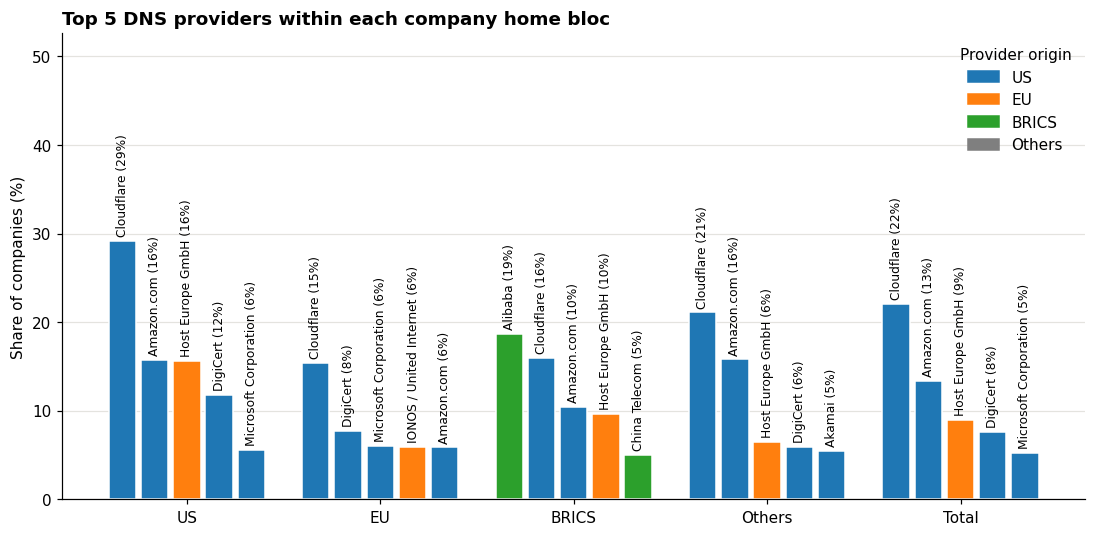

In [35]:
# GRÁFICO 1: os principais provedores de CADA bloco (eixo X = blocos)
# Cada bloco tem os seus próprios maiores provedores (ex.: Alibaba aparece só no BRICS),
# então aqui eu pego os TOP_N maiores dentro de cada bloco, e não os maiores do Total.
TOP_N = 5   # quantos provedores mostrar por bloco (com 1, fica só o principal de cada bloco)

# ordeno do maior para o menor e fico com as TOP_N primeiras linhas de cada bloco
top_por_bloco = (por_provedor.sort_values("participacao", ascending=False)
                             .groupby("bloco_empresa")
                             .head(TOP_N)
                             .copy())

# coloco os blocos na ordem US, EU, BRICS, Others, Total (e, dentro de cada um, do maior para o menor)
top_por_bloco["bloco_empresa"] = pd.Categorical(top_por_bloco["bloco_empresa"], categories=ORDEM_BLOCOS, ordered=True)
top_por_bloco = top_por_bloco.sort_values(["bloco_empresa", "participacao"], ascending=[True, False])

# nome curto do provedor para o rótulo (corto o que vem depois da vírgula: "Cloudflare, Inc." -> "Cloudflare")
top_por_bloco["nome_curto"] = top_por_bloco["provedor"].str.split(",").str[0]

# origem do provedor (bloco do país do provedor), que vai definir a cor da barra
origem_provedor = ep.drop_duplicates("provedor").set_index("provedor")["bloco_provedor"]
top_por_bloco["bloco_provedor"] = top_por_bloco["provedor"].map(origem_provedor)

display(top_por_bloco[["bloco_empresa", "provedor", "bloco_provedor", "participacao"]].round(1))
salvar_tabela(top_por_bloco[["bloco_empresa", "provedor", "bloco_provedor", "participacao"]], "conc_top_provedores_por_bloco")

# a cor da barra mostra a ORIGEM do provedor (bloco do país do provedor), com as cores padrão dos blocos

fig, ax = plt.subplots(figsize=(12, 5.5))

x = 0                    # posição da próxima barra no eixo X
centros_dos_blocos = []  # posição do meio de cada bloco, onde vai o rótulo do eixo X

for bloco in ORDEM_BLOCOS:
    dados = top_por_bloco[top_por_bloco["bloco_empresa"] == bloco]
    posicoes = range(x, x + len(dados))

    barras = ax.bar(posicoes, dados["participacao"], width=0.85,
                    color=dados["bloco_provedor"].map(CORES_BLOCOS), edgecolor="white")

    # escrevo o nome do provedor e a participação em cima de cada barra (na vertical)
    ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados["participacao"])],
                 rotation=90, padding=3, fontsize=8)

    centros_dos_blocos.append(x + (len(dados) - 1) / 2)
    x += len(dados) + 1  # deixo uma posição vazia entre um bloco e outro

ax.set_xticks(centros_dos_blocos)
ax.set_xticklabels(rotulos_sem_n(n_empresas))
ax.set_ylim(0, top_por_bloco["participacao"].max() * 1.8)   # espaço para os nomes em cima das barras
ax.set_title(f"Top {TOP_N} DNS providers within each company home bloc")
ax.set_ylabel(f"Share of {UNIDADE} (%)")

# legenda das cores: um quadradinho para cada bloco de origem do provedor
from matplotlib.patches import Patch
legenda = [Patch(color=CORES_BLOCOS[b], label=b) for b in ["US", "EU", "BRICS", "Others"]]
ax.legend(handles=legenda, title="Provider origin", loc="upper right")

salvar_figura(fig, "fig_conc_top_provedores")
plt.show()

## 4. HHI e nº efetivo de provedores por bloco

Para o HHI, as participações de cada bloco precisam somar 100%. Nos métodos `fracionado` e
`principal` isso já acontece. No método `uso` eu recalculo a participação dividindo pelo total
de `valor` do bloco, ou seja, a fatia de cada provedor no total de **relações empresa–provedor**.

Para cada bloco calculo:
- `HHI` = soma de (participação em %)²
- `n_efetivo` = 10.000 ÷ HHI
- `top1`, `top5` e `top10`: fatia (%) do maior, dos 5 maiores e dos 10 maiores provedores

In [25]:
# participação (%) que soma 100 dentro de cada bloco
por_provedor["part_100"] = 100 * por_provedor["valor"] / por_provedor.groupby("bloco_empresa")["valor"].transform("sum")

# posição do provedor dentro do bloco (1 = maior)
por_provedor["posicao"] = por_provedor.groupby("bloco_empresa")["part_100"].rank(ascending=False, method="first")

# o HHI é a soma dos quadrados das participações
por_provedor["part_ao_quadrado"] = por_provedor["part_100"] ** 2

tab_hhi = pd.DataFrame({
    "n_companies": n_empresas,
    "n_providers": por_provedor.groupby("bloco_empresa")["provedor"].nunique(),
    "HHI": por_provedor.groupby("bloco_empresa")["part_ao_quadrado"].sum(),
}).reindex(ORDEM_BLOCOS)

tab_hhi["n_efetivo"] = 10_000 / tab_hhi["HHI"]

# fatia do maior, dos 5 maiores e dos 10 maiores provedores
for k in [1, 5, 10]:
    tab_hhi[f"top{k}"] = por_provedor[por_provedor["posicao"] <= k].groupby("bloco_empresa")["part_100"].sum()

display(tab_hhi.round(1))
salvar_tabela(tab_hhi, "conc_hhi_blocos")

,n_companies,n_providers,HHI,n_efetivo,top1,top5,top10
bloco_empresa,,,,,,,
US,3257,264,1552.2,6.4,29.2,78.0,88.6
EU,1782,400,491.5,20.3,15.4,41.0,58.7
BRICS,1281,182,902.7,11.1,18.7,59.7,75.9
Others,3963,472,865.3,11.6,21.1,54.7,68.7
Total,10283,1113,878.5,11.4,22.1,57.3,69.1


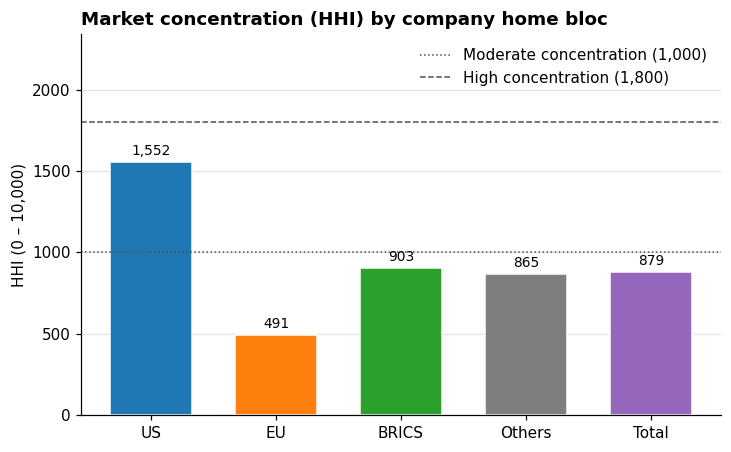

In [26]:
# GRÁFICO 2: HHI por bloco, com as linhas de referência de 1.000 e 1.800
fig, ax = plt.subplots(figsize=(7.5, 4.5))
barras = ax.bar(rotulos_sem_n(n_empresas), tab_hhi["HHI"],
                color=[CORES_BLOCOS[b] for b in tab_hhi.index], edgecolor="white", width=0.65)

# escrevo em cima de cada barra o HHI e o nº efetivo de provedores
ax.bar_label(barras, labels=[f"{h:,.0f}" for h in (tab_hhi["HHI"])],
             padding=3, fontsize=9)

# linhas de referência (aparecem na legenda)
ax.axhline(1000, color="#52514e", linestyle=":", linewidth=1, label="Moderate concentration (1,000)")
ax.axhline(1800, color="#52514e", linestyle="--", linewidth=1, label="High concentration (1,800)")
ax.legend(loc="upper right")

ax.set_ylim(0, max(tab_hhi["HHI"].max(), 1800) * 1.3)
ax.set_title("Market concentration (HHI) by company home bloc")
ax.set_ylabel("HHI (0 – 10,000)")

salvar_figura(fig, "fig_conc_hhi_blocos")
plt.show()

## 5. Quanto do mercado fica com os maiores provedores?

Divido os provedores de cada bloco em faixas pela posição (1º, 2º ao 5º, 6º ao 10º e o resto)
e somo a participação de cada faixa. Cada barra soma 100%.

In [27]:
# classifico cada provedor em uma faixa, conforme a sua posição dentro do bloco
por_provedor["faixa"] = pd.cut(por_provedor["posicao"],
                               bins=[0, 1, 5, 10, float("inf")],
                               labels=["Largest provider", "2nd to 5th", "6th to 10th", "All others"])

tab_faixas = (por_provedor.pivot_table(index="bloco_empresa", columns="faixa", values="part_100",
                                       aggfunc="sum", observed=False)
                          .reindex(ORDEM_BLOCOS))

display(tab_faixas.round(1))
salvar_tabela(tab_faixas, "conc_faixas_blocos")

faixa,Largest provider,2nd to 5th,6th to 10th,All others
bloco_empresa,,,,
US,29.2,48.8,10.6,11.4
EU,15.4,25.5,17.7,41.3
BRICS,18.7,41.0,16.1,24.1
Others,21.1,33.6,13.9,31.3
Total,22.1,35.2,11.8,30.9


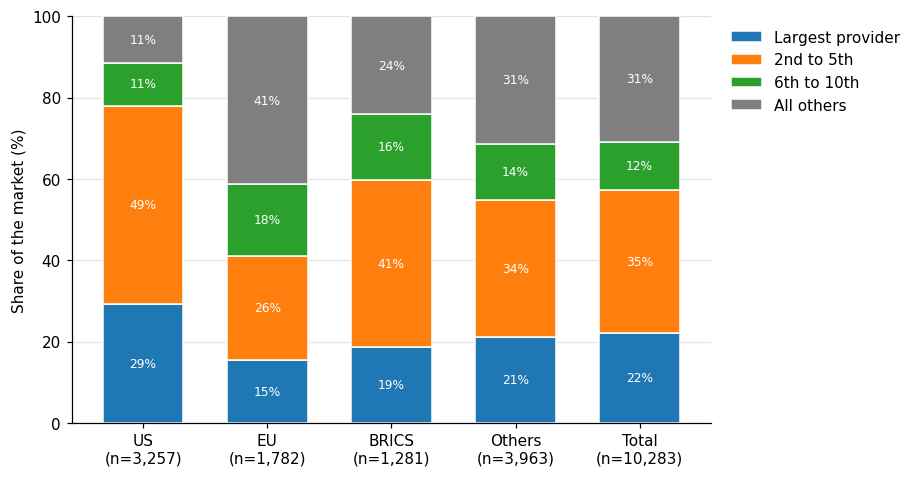

In [28]:
# GRÁFICO 3: barras empilhadas (cada barra = um bloco, soma 100%)
cores_faixas = [PALETA[0], PALETA[1], PALETA[2], PALETA[7]]

fig, ax = plt.subplots(figsize=(7.5, 4.8))
tab_faixas.plot.bar(ax=ax, stacked=True, width=0.65, color=cores_faixas, edgecolor="white")

# escrevo o % dentro de cada pedaço (só nos pedaços com 4% ou mais, para não poluir)
for pedacos in ax.containers:
    ax.bar_label(pedacos, labels=[f"{v:.0f}%" if v >= 4 else "" for v in pedacos.datavalues],
                 label_type="center", fontsize=8, color="white")

#ax.set_title("How much of the market goes to the largest providers")
ax.grid(axis="x", visible=False)   # o pandas liga a grade vertical; deixo só a horizontal
ax.set_xlabel("")
ax.set_ylabel("Share of the market (%)")
ax.set_xticklabels(rotulos_com_n(n_empresas), rotation=0)
ax.set_ylim(0, 100)
ax.legend(title="Provider rank within the bloc", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
salvar_figura(fig, "fig_conc_faixas_blocos")
plt.show()


## 6. Notas para a leitura

- O **Total** mistura mercados diferentes (países, idiomas, regulação). Por isso a comparação
  entre blocos é a leitura principal.
- O país do provedor é o país do **grupo controlador** do ASN, e não onde ficam os servidores
  (provedores *anycast*, como Cloudflare e Akamai, têm servidores no mundo todo).
- Para gerar as outras versões, basta mudar `METODO` e/ou `PONDERAR_POR_RECEITA` na primeira
  célula de código e rodar tudo de novo. Os arquivos saem com o sufixo da versão no nome.

## 7. Visão dos provedores: ocorrências nos dados

Nesta seção olho do ponto de vista dos **provedores** (grupo econômico dono dos AS, `dp_as_org`,
o mesmo "provedor" das seções anteriores), mas contando a **infraestrutura**: quantas vezes cada
provedor aparece hospedando os servidores de nomes das empresas de cada bloco.

Lembrando a relação: cada AS pertence a uma única organização (`as_org`), uma organização pode ter
vários AS, e o grupo econômico junta várias organizações (ex.: as duas organizações do Alibaba,
ou as subsidiárias da Leaseweb em cada país).

| Coluna | O que é | Exemplo |
|---|---|---|
| `server_example` | servidor de nomes (NS) mais comum daquele provedor no bloco | ns3.google.com |
| `organization` | grupo econômico dono dos AS (`dp_as_org`) | Google LLC |
| `asn` | número(s) dos AS do provedor que aparecem no bloco | 15169 |
| `as_country` | país do provedor (`dp_as_country_code`) | US |
| `occurrences` | nº de ocorrências do provedor nos dados do bloco (linhas empresa × NS × IP) | 30,812 |
| `centralization_pct` | % que essas ocorrências representam no total do bloco | 35% |
| `n_companies` / `companies_pct` | nº e % de empresas do bloco com pelo menos um NS nesse provedor | |

> Esta seção conta **ocorrências** (linhas do dataset), e não empresas. Por isso ela **não depende**
> de `METODO` nem de `PONDERAR_POR_RECEITA`: uma empresa com 8 NS conta 8 vezes, uma com 2 conta 2.
> A coluna `companies_pct` ajuda a ver o mesmo provedor do ponto de vista das empresas.

In [29]:
# mesma ideia da seção 2: duplico as linhas trocando o bloco por "Total"
df_total = pd.concat([df, df.assign(bloco_empresa="Total")], ignore_index=True)


def mais_comum(serie):
    """Devolve o valor que mais aparece na série."""
    return serie.value_counts().index[0]


def lista_asn(serie):
    """Junta os ASNs diferentes em um texto, ex.: '16509, 14618'."""
    return ", ".join(str(a) for a in sorted(serie.unique()))


# uma linha por (bloco da empresa, provedor = grupo econômico dono dos AS)
tab_org = (df_total.groupby(["bloco_empresa", "provedor"], as_index=False)
                   .agg(server_example=("ns", mais_comum),               # NS mais frequente
                        asn=("asn", lista_asn),                          # AS do provedor no bloco
                        as_country=("pais_provedor", mais_comum),
                        occurrences=("ns", "size"),                      # nº de linhas (empresa x NS x IP)
                        n_companies=("rank", "nunique"))
                   .rename(columns={"provedor": "organization"}))

# centralização = ocorrências do provedor / total de ocorrências do bloco
tab_org["centralization_pct"] = 100 * tab_org["occurrences"] / tab_org.groupby("bloco_empresa")["occurrences"].transform("sum")

# % das empresas do bloco que têm pelo menos um NS nesse provedor
tab_org["companies_pct"] = 100 * tab_org["n_companies"] / tab_org["bloco_empresa"].map(n_empresas)

# blocos na ordem padrão e, dentro de cada um, do provedor com mais ocorrências para o com menos
tab_org["bloco_empresa"] = pd.Categorical(tab_org["bloco_empresa"], categories=ORDEM_BLOCOS, ordered=True)
tab_org = tab_org.sort_values(["bloco_empresa", "occurrences"], ascending=[True, False])
tab_org["position"] = tab_org.groupby("bloco_empresa", observed=True).cumcount() + 1   # 1 = maior do bloco

COLUNAS_ORG = ["bloco_empresa", "position", "server_example", "organization", "asn",
               "as_country", "occurrences", "centralization_pct", "n_companies", "companies_pct"]
tab_org = tab_org[COLUNAS_ORG]

# como esta tabela não muda com METODO/PONDERAR_POR_RECEITA, salvo sem o sufixo da versão
tab_org.to_csv(PASTA_TAB / "conc_org_ocorrencias.csv", index=False)
print(f"{tab_org['organization'].nunique():,} provedores diferentes nos dados")

1,113 provedores diferentes nos dados


In [30]:
# TABELA DE VISUALIZAÇÃO: os maiores provedores de cada bloco (no formato da tabela do artigo)
TOP_ORG = 3   # quantos provedores mostrar por bloco

top_org = tab_org[tab_org["position"] <= TOP_ORG]
display(top_org.style
               .format({"occurrences": "{:,}", "n_companies": "{:,}",
                        "centralization_pct": "{:.1f}%", "companies_pct": "{:.1f}%"})
               .hide(axis="index"))

bloco_empresa,position,server_example,organization,asn,as_country,occurrences,centralization_pct,n_companies,companies_pct
US,1,blue.foundationdns.com,"Cloudflare, Inc.",13335,US,"4,577",34.8%,960,29.5%
US,2,ns1.siteground.net,"Amazon.com, Inc.","14618, 16509",US,"2,032",15.5%,522,16.0%
US,3,ns0.dnsmadeeasy.com,DigiCert,"12008, 16552, 19905, 399153, 399154",US,"1,621",12.3%,403,12.4%
EU,1,blue.foundationdns.com,"Cloudflare, Inc.",13335,US,"1,567",23.3%,285,16.0%
EU,2,a28-65.akam.net,Akamai,"21342, 63949",US,490,7.3%,84,4.7%
EU,3,ns1-02.azure-dns.com,Microsoft Corporation,"8069, 8075",US,427,6.3%,121,6.8%
BRICS,1,vip4.alidns.com,Alibaba,"37963, 45102, 134963",CN,"2,984",34.1%,249,19.4%
BRICS,2,john.ns.cloudflare.com,"Cloudflare, Inc.",13335,US,"1,472",16.8%,207,16.2%
BRICS,3,ns3.dnsv5.com,Tencent,"45090, 132203",CN,645,7.4%,94,7.3%
Others,1,roan.ns.cloudflare.com,"Cloudflare, Inc.",13335,US,"4,497",29.1%,856,21.6%


In [31]:
# TABELA DE VISUALIZAÇÃO: os 10 maiores provedores do Total, comparados entre os blocos
# (cada célula = % das ocorrências do bloco que caem naquele provedor)
maiores_total = tab_org[(tab_org["bloco_empresa"] == "Total") & (tab_org["position"] <= 10)]["organization"]

tab_org_blocos = (tab_org[tab_org["organization"].isin(maiores_total)]
                  .pivot_table(index="organization", columns="bloco_empresa",
                               values="centralization_pct", aggfunc="sum", observed=False)
                  .reindex(columns=ORDEM_BLOCOS)
                  .fillna(0)
                  .sort_values("Total", ascending=False))

# o degradê de cor ajuda a achar os valores mais altos de cada coluna
display(tab_org_blocos.style.format("{:.1f}%").background_gradient(cmap="Blues", axis=0))
tab_org_blocos.to_csv(PASTA_TAB / "conc_org_top10_blocos.csv")

bloco_empresa,US,EU,BRICS,Others,Total
organization,,,,,
"Cloudflare, Inc.",34.8%,23.3%,16.8%,29.1%,27.5%
"Amazon.com, Inc.",15.5%,6.3%,6.7%,15.9%,12.5%
Alibaba,0.1%,0.0%,34.1%,1.7%,7.4%
Akamai,7.8%,7.3%,3.9%,8.3%,7.1%
DigiCert,12.3%,6.2%,1.1%,5.0%,6.6%
Microsoft Corporation,5.5%,6.3%,1.6%,5.5%,4.9%
Host Europe GmbH,7.8%,1.0%,2.9%,3.3%,4.2%
Tencent,0.0%,0.0%,7.4%,0.3%,1.6%
NSONE Inc,2.8%,1.3%,0.1%,1.4%,1.5%


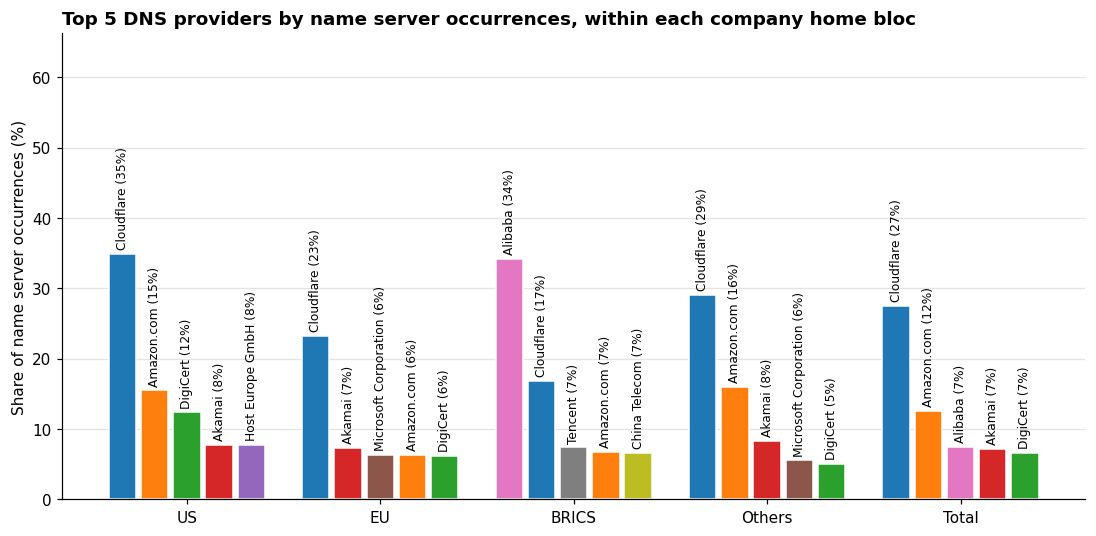

In [32]:
# GRÁFICO 4: os maiores provedores de cada bloco, pela centralização (mesmo formato do gráfico 1)
TOP_ORG_GRAFICO = 5

dados_grafico = tab_org[tab_org["position"] <= TOP_ORG_GRAFICO].copy()

# nome curto para o rótulo (o que vem antes da vírgula: "Cloudflare, Inc." -> "Cloudflare")
dados_grafico["nome_curto"] = dados_grafico["organization"].str.split(",").str[0]

# uma cor para cada provedor, que se repete em todos os blocos
orgs_no_grafico = dados_grafico["organization"].unique()
COR_ORG = {org: PALETA[i % len(PALETA)] for i, org in enumerate(orgs_no_grafico)}

fig, ax = plt.subplots(figsize=(12, 5.5))

x = 0                    # posição da próxima barra no eixo X
centros_dos_blocos = []  # posição do meio de cada bloco, onde vai o rótulo do eixo X

for bloco in ORDEM_BLOCOS:
    dados = dados_grafico[dados_grafico["bloco_empresa"] == bloco]
    posicoes = range(x, x + len(dados))

    barras = ax.bar(posicoes, dados["centralization_pct"], width=0.85,
                    color=dados["organization"].map(COR_ORG), edgecolor="white")

    # rótulo: "Cloudflare (35%)"
    ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados["centralization_pct"])],
                 rotation=90, padding=3, fontsize=8)

    centros_dos_blocos.append(x + (len(dados) - 1) / 2)
    x += len(dados) + 1  # deixo uma posição vazia entre um bloco e outro

ax.set_xticks(centros_dos_blocos)
ax.set_xticklabels(rotulos_sem_n(n_empresas))
ax.set_ylim(0, dados_grafico["centralization_pct"].max() * 1.9)   # espaço para os rótulos
ax.set_title(f"Top {TOP_ORG_GRAFICO} DNS providers by name server occurrences, within each company home bloc")
ax.set_ylabel("Share of name server occurrences (%)")

# figura sem o sufixo da versão, pelo mesmo motivo da tabela
fig.savefig(PASTA_FIG / "fig_conc_top_org.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.1 Os 5 países com maior receita

Mesma visão de ocorrências, mas olhando país por país. Escolho os 5 países cujas empresas, somadas,
têm a maior receita (`revenue_ttm`) e mostro os 5 maiores provedores (`dp_as_org`) de cada um.

In [33]:
TOP_PAISES = 5        # quantos países mostrar
TOP_PROV_PAIS = 5     # quantos provedores mostrar por país

# receita total de cada país (cada empresa contada uma vez só)
receita_pais = (df.drop_duplicates("rank")
                  .groupby("company_country")["revenue_ttm"].sum()
                  .sort_values(ascending=False))
maiores_paises = receita_pais.head(TOP_PAISES).index.tolist()
print("Países:", maiores_paises)

# uma linha por (país da empresa, provedor), só para os países escolhidos
df_paises = df[df["company_country"].isin(maiores_paises)]
tab_paises = (df_paises.groupby(["company_country", "provedor"], as_index=False)
                       .agg(bloco_provedor=("bloco_provedor", "first"),   # origem do provedor
                            occurrences=("ns", "size"),
                            n_companies=("rank", "nunique")))

# centralização = ocorrências do provedor / total de ocorrências do país
tab_paises["centralization_pct"] = 100 * tab_paises["occurrences"] / tab_paises.groupby("company_country")["occurrences"].transform("sum")

# % das empresas do país que têm pelo menos um NS nesse provedor
empresas_pais = df_paises.groupby("company_country")["rank"].nunique()
tab_paises["companies_pct"] = 100 * tab_paises["n_companies"] / tab_paises["company_country"].map(empresas_pais)

# países do mais rico para o menos rico e, dentro de cada um, do maior provedor para o menor
tab_paises["company_country"] = pd.Categorical(tab_paises["company_country"], categories=maiores_paises, ordered=True)
tab_paises = tab_paises.sort_values(["company_country", "occurrences"], ascending=[True, False])
tab_paises["position"] = tab_paises.groupby("company_country", observed=True).cumcount() + 1

top_paises = tab_paises[tab_paises["position"] <= TOP_PROV_PAIS]
display(top_paises.style
                  .format({"occurrences": "{:,}", "n_companies": "{:,}",
                           "centralization_pct": "{:.1f}%", "companies_pct": "{:.1f}%"})
                  .hide(axis="index"))
top_paises.to_csv(PASTA_TAB / "conc_org_top_paises_receita.csv", index=False)

Países: ['United States', 'China', 'Japan', 'Germany', 'United Kingdom']


company_country,provedor,bloco_provedor,occurrences,n_companies,centralization_pct,companies_pct,position
United States,"Cloudflare, Inc.",US,"4,577",960,34.8%,29.5%,1
United States,"Amazon.com, Inc.",US,"2,032",522,15.5%,16.0%,2
United States,DigiCert,US,"1,621",403,12.3%,12.4%,3
United States,Akamai,US,"1,022",173,7.8%,5.3%,4
United States,Host Europe GmbH,EU,"1,022",511,7.8%,15.7%,5
China,Alibaba,BRICS,"2,960",247,56.5%,51.1%,1
China,Tencent,BRICS,645,94,12.3%,19.5%,2
China,China Telecom,BRICS,573,158,10.9%,32.7%,3
China,China Unicom,BRICS,380,166,7.2%,34.4%,4
China,China Mobile,BRICS,261,116,5.0%,24.0%,5


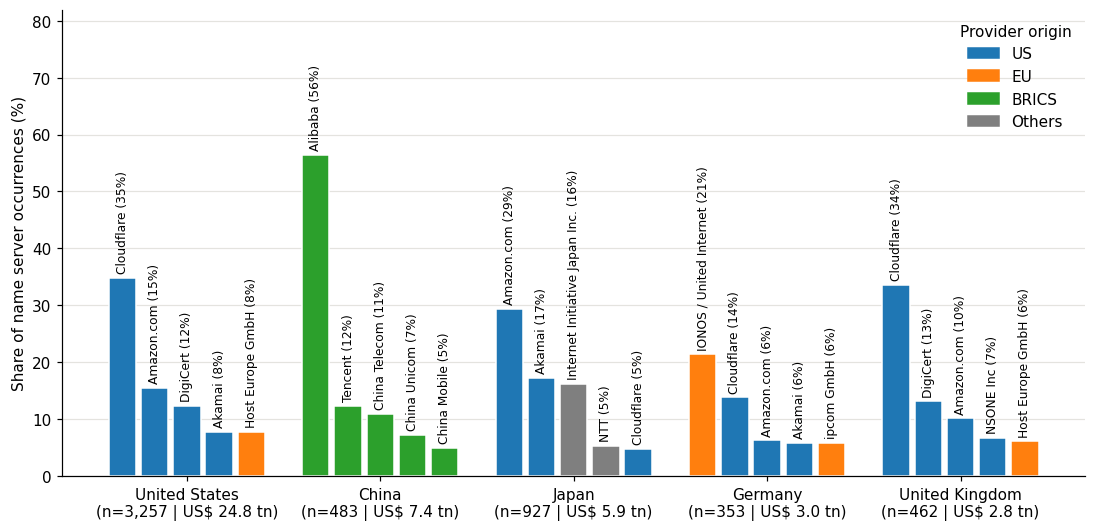

In [34]:
# GRÁFICO 5: os maiores provedores dos países com maior receita (mesmo formato do gráfico 4)
dados_grafico = top_paises.copy()
dados_grafico["nome_curto"] = dados_grafico["provedor"].str.split(",").str[0]

# a cor da barra mostra a ORIGEM do provedor (bloco do país do provedor), com as cores padrão dos blocos

fig, ax = plt.subplots(figsize=(12, 5.5))

x = 0                     # posição da próxima barra no eixo X
centros_dos_paises = []   # posição do meio de cada país, onde vai o rótulo do eixo X

for pais in maiores_paises:
    dados = dados_grafico[dados_grafico["company_country"] == pais]
    posicoes = range(x, x + len(dados))

    barras = ax.bar(posicoes, dados["centralization_pct"], width=0.85,
                    color=dados["bloco_provedor"].map(CORES_BLOCOS), edgecolor="white")

    # rótulo: "Cloudflare (35%)"
    ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados["centralization_pct"])],
                 rotation=90, padding=3, fontsize=8)

    centros_dos_paises.append(x + (len(dados) - 1) / 2)
    x += len(dados) + 1  # deixo uma posição vazia entre um país e outro

# rótulo do eixo X: país, nº de empresas e receita total (em trilhões de dólares)
ax.set_xticks(centros_dos_paises)
ax.set_xticklabels([f"{p}\n(n={empresas_pais[p]:,} | US$ {receita_pais[p] / 1e12:.1f} tn)" for p in maiores_paises])
ax.set_ylim(0, dados_grafico["centralization_pct"].max() * 1.45)   # espaço para os rótulos
#ax.set_title(f"Top {TOP_PROV_PAIS} DNS providers in the {TOP_PAISES} countries with the highest company revenue")
ax.set_ylabel("Share of name server occurrences (%)")

# legenda das cores: um quadradinho para cada bloco de origem do provedor
from matplotlib.patches import Patch
legenda = [Patch(color=CORES_BLOCOS[b], label=b) for b in ["US", "EU", "BRICS", "Others"]]
ax.legend(handles=legenda, title="Provider origin", loc="upper right")

fig.savefig(PASTA_FIG / "fig_conc_top_paises_receita.png", dpi=200, bbox_inches="tight")
plt.show()